# Issue polarization

Roadmap step 3, part 1. Which issues divide the parties, how did that change, and did polarization rise because the **agenda** changed or because voting **within** issues changed?

Steps 1 and 2 raised the agenda question but couldn't test it.

**Topics** use the six Clausen categories in Voteview's JSON export. They cover every roll call through the Congress beginning in 2013 and none after, so this part covers 1857 to 2014. Notebook 02 extends topics past 2014 with a classifier.

**Vote types** come from Voteview's `vote_question`, grouped into broad types such as passage, amendment, procedural, suspension, cloture and nomination. The mapping is documented in the data loading docs. They are available from 1991, so that part covers 1991 to 2023.

The measure is the share of contested roll calls on which party majorities voted on opposite sides, as in notebook 01 of polarization_clustering. Scope and the 2.5% cutoff match the earlier steps.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from explanation import ROLLCALL_KEYS, first_year, party_shares, shift_share
from voteview import load_members, load_rollcalls, load_topics, load_votes

COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
CHAMBER_COLORS = {"House": "#2a78d6", "Senate": "#c93b3b"}
INCOMPLETE_CONGRESS = 119
LAST_CLAUSEN_CONGRESS = 113
MIN_PARTY_MEMBERS = 10
MIN_ROLLCALLS = 10
CHAMBERS = ["House", "Senate"]
TOPICS = ["Government Management", "Foreign and Defense Policy", "Social Welfare", "Civil Liberties", "Agriculture", "Miscellaneous Policy"]
VOTE_TYPES = ["passage", "amendment", "procedural", "suspension", "resolution", "cloture", "nomination", "conference report"]

members = load_members()
members = members[~members["is_delegate"]]
counts = members.groupby(["congress", "chamber"])["party"].value_counts().unstack(fill_value=0)
selected = counts[(counts["D"] >= MIN_PARTY_MEMBERS) & (counts["R"] >= MIN_PARTY_MEMBERS)].index

votes = load_votes().merge(members[["congress", "chamber", "icpsr", "party"]], on=["congress", "chamber", "icpsr"])
rollcalls = load_rollcalls().set_index(ROLLCALL_KEYS)
shares = party_shares(votes).join(rollcalls[["is_lopsided"]]).join(load_topics().set_index(ROLLCALL_KEYS)[["clausen", "vote_type"]])
del votes
shares = shares[~shares["is_lopsided"]]
shares = shares[pd.MultiIndex.from_arrays([shares.index.get_level_values(0), shares.index.get_level_values(1)]).isin(selected)]
shares["opposed"] = (shares["D"] - 0.5) * (shares["R"] - 0.5) < 0
shares["cross_agreement"] = shares["D"] * shares["R"] + (1 - shares["D"]) * (1 - shares["R"])
shares = shares.reset_index()
shares["year"] = first_year(shares["congress"])
print(f"{len(shares):,} contested roll calls in {shares.groupby(['congress', 'chamber']).ngroups} Congress and chamber combinations")
through_2014 = shares[shares["congress"] <= LAST_CLAUSEN_CONGRESS]
print(f"Of these, {len(through_2014):,} are from Congresses beginning in 2013 or earlier; "
      f"{through_2014['clausen'].notna().mean():.2%} of those have a Clausen topic. None after 2014 do.")


82,576 contested roll calls in 170 Congress and chamber combinations
Of these, 73,067 are from Congresses beginning in 2013 or earlier; 100.00% of those have a Clausen topic. None after 2014 do.


73,067 contested roll calls from 1857 to 2014 all have a Clausen topic. The other 9,509 contested roll calls, from 2015 on, have none.

## Party division by topic, 1857 to 2014

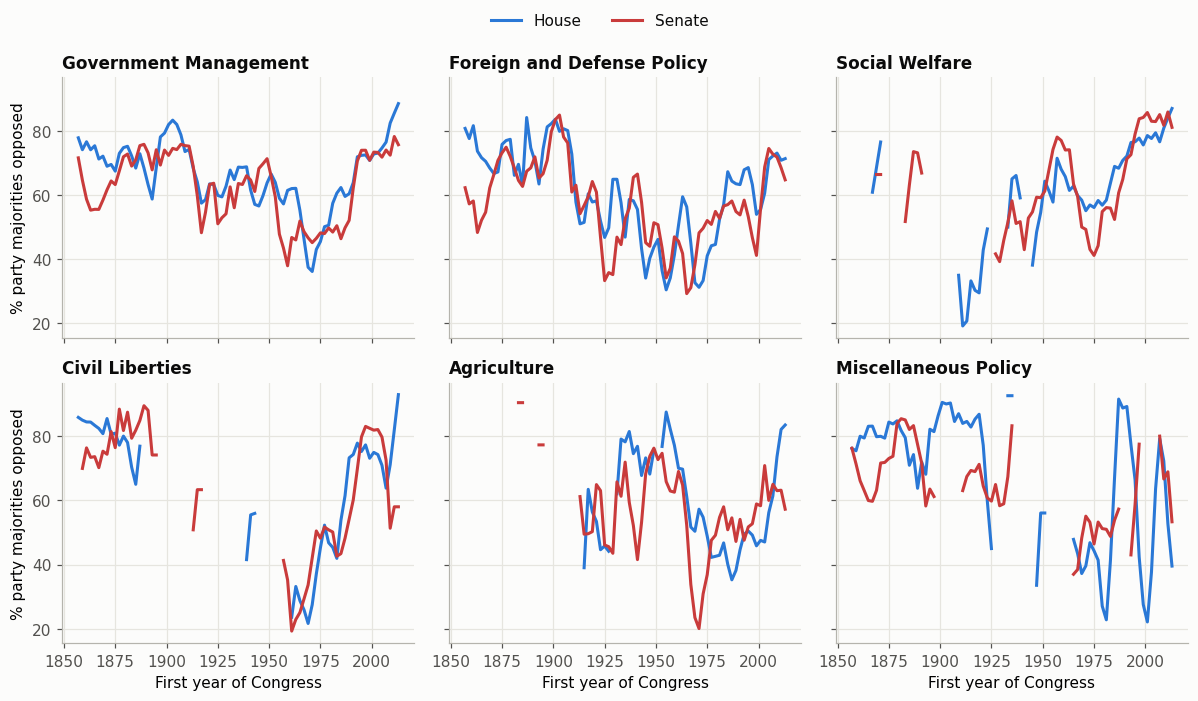

Lines are three-Congress averages. Congresses with fewer than 10 contested roll calls on a topic are left out, and longer runs of them show as gaps.


In [2]:
coded = shares[shares["congress"] <= LAST_CLAUSEN_CONGRESS].dropna(subset=["clausen"])
by_topic = coded.groupby(["chamber", "congress", "year", "clausen"]).agg(
    rollcalls=("opposed", "size"), party_opposed=("opposed", "mean"), cross_agreement=("cross_agreement", "mean")).reset_index()
by_topic = by_topic[by_topic["rollcalls"] >= MIN_ROLLCALLS]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharex=True, sharey=True)
for axis, topic in zip(axes.flat, TOPICS):
    for chamber in CHAMBERS:
        data = by_topic[(by_topic["clausen"] == topic) & (by_topic["chamber"] == chamber)].set_index("year")["party_opposed"]
        # Reindex to every Congress so that runs of thin Congresses show as gaps instead of straight lines.
        every_year = sorted(by_topic.loc[by_topic["chamber"] == chamber, "year"].unique())
        smooth = data.reindex(every_year).rolling(3, center=True, min_periods=2).mean()
        axis.plot(smooth.index, smooth * 100, color=CHAMBER_COLORS[chamber], label=chamber)
    axis.set_title(topic)
for axis in axes[1]:
    axis.set_xlabel("First year of Congress")
for axis in axes[:, 0]:
    axis.set_ylabel("% party majorities opposed")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
print("Lines are three-Congress averages. Congresses with fewer than 10 contested roll calls on a topic are left out, and longer runs of them show as gaps.")


**What this shows**

- **Most topics followed the broad U-shape**: divided around 1900, less divided at mid-century, and divided again by the 2000s.
- **There are exceptions:**
  - **House Social Welfare rose almost throughout:** 48% opposed in 1901 to 1911, 57% in 1965 to 1975, 81% in 2003 to 2013.
  - House Agriculture and Miscellaneous Policy reached their lowest points late, around 1987 and 2001.
- **The lowest points also differ by topic.** Civil Liberties was least divided around 1961 to 1969, and Foreign and Defense Policy around 1955 to 1965.
- Small topics (Agriculture, Civil Liberties, Miscellaneous) are noisy, with gaps where there were too few contested roll calls.

In [3]:
rows = []
for (chamber, topic), frame in by_topic.groupby(["chamber", "clausen"]):
    frame = frame.sort_values("year").set_index("year")
    smooth = frame["party_opposed"].rolling(3, center=True, min_periods=2).mean()
    since_1900 = smooth[smooth.index >= 1900]
    pooled = lambda low, high: coded[(coded["chamber"] == chamber) & (coded["clausen"] == topic) & coded["year"].between(low, high)]["opposed"].mean()
    rows.append({
        "chamber": chamber, "topic": topic,
        "closest_year": since_1900.idxmin(), "lowest_opposed": since_1900.min(),
        "opposed_1901_1911": pooled(1901, 1911),
        "opposed_1965_1975": pooled(1965, 1975),
        "opposed_2003_2013": pooled(2003, 2013),
        "rollcalls_2003_2013": ((coded["chamber"] == chamber) & (coded["clausen"] == topic) & coded["year"].between(2003, 2013)).sum(),
    })
topic_table = pd.DataFrame(rows).set_index(["chamber", "topic"])
display(topic_table.round(3))


closest_year  lowest_opposed  \
chamber topic                                                      
House   Agriculture                         1987           0.353   
        Civil Liberties                     1969           0.217   
        Foreign and Defense Policy          1955           0.305   
        Government Management               1971           0.362   
        Miscellaneous Policy                2001           0.222   
        Social Welfare                      1913           0.208   
Senate  Agriculture                         1971           0.201   
        Civil Liberties                     1961           0.193   
        Foreign and Defense Policy          1965           0.293   
        Government Management               1959           0.380   
        Miscellaneous Policy                1963           0.384   
        Social Welfare                      1925           0.340   

                                    opposed_1901_1911  opposed_1965_1975  \
chamber topic                                                              
House   Agriculture                             0.769              0.515   
        Civil Liberties                         0.758              0.327   
        Foreign and Defense Policy              0.722              0.373   
        Government Management                   0.764              0.454   
        Miscellaneous Policy                    0.890              0.465   
        Social Welfare                          0.477              0.566   
Senate  Agriculture                             0.667              0.340   
        Civil Liberties                         0.550              0.416   
        Foreign and Defense Policy              0.665              0.435   
        Government Management                   0.752              0.474   
        Miscellaneous Policy                    0.600              0.457   
        Social Welfare                          0.674              0.516   

                                    opposed_2003_2013  rollcalls_2003_2013  
chamber topic                                                               
House   Agriculture                             0.724                  196  
        Civil Liberties                         0.752                  258  
        Foreign and Defense Policy              0.713                 1260  
        Government Management                   0.818                 3729  
        Miscellaneous Policy                    0.656                  433  
        Social Welfare                          0.813                  690  
Senate  Agriculture                             0.641                  103  
        Civil Liberties                         0.700                  150  
        Foreign and Defense Policy              0.734                  571  
        Government Management                   0.765                 1773  
        Miscellaneous Policy                    0.627                   51  
        Social Welfare                          0.855                  519

**What this shows**

- **From 2003 to 2013, the most divided topics were Social Welfare** (81% of contested roll calls in the House, 86% in the Senate) **and Government Management** (82% and 77%). Government Management covers budgets, taxes and how government runs, and is over half of all contested votes.
- **Foreign and Defense Policy, Agriculture and Miscellaneous Policy were relatively less divided** at 63% to 73%, but still well above their mid-century levels.
- **Social Welfare was the least convergent topic at mid-century:** 57% opposed in the House and 52% in the Senate from 1965 to 1975, the highest of any topic in each chamber then.
- **Large swings:**
  - In the House, Civil Liberties swung the most: from 76% (1901 to 1911) to 33% (1965 to 1975) to 75% (2003 to 2013).
  - In the Senate, Agriculture swung more (67%, 34%, 64%) than Civil Liberties (55%, 42%, 70%).

## Did the agenda change, or did voting within topics change?

In [4]:
mix = coded.groupby(["chamber", pd.cut(coded["year"], [1856, 1900, 1936, 1964, 1980, 2000, 2014],
                                          labels=["1857-1899", "1901-1935", "1937-1963", "1965-1979", "1981-1999", "2001-2013"])], observed=True)["clausen"].value_counts(normalize=True).unstack()
print("Topic mix of contested roll calls (share of each period)")
display(mix[TOPICS].round(3))


def rates_and_weights(frame, column):
    grouped = frame.groupby(column)["opposed"].agg(["mean", "size"])
    return pd.DataFrame({"rate": grouped["mean"], "weight": grouped["size"] / grouped["size"].sum()})


def decompose(frame, column, periods):
    rows = []
    for chamber in CHAMBERS:
        part = frame[frame["chamber"] == chamber]
        for name, (early, late) in periods.items():
            before = rates_and_weights(part[part["year"].between(*early)], column)
            after = rates_and_weights(part[part["year"].between(*late)], column)
            rows.append({"chamber": chamber, "change": name, **shift_share(before, after)})
    table = pd.DataFrame(rows).set_index(["chamber", "change"])
    table["mix_share"] = table["topic_mix"] / table["total"]
    return table


PERIODS = {
    "1901-1905 to 1967-1971": ((1901, 1905), (1967, 1971)), "1903-1907 to 1965-1969": ((1903, 1907), (1965, 1969)),
    "1967-1971 to 2009-2013": ((1967, 1971), (2009, 2013)), "1965-1969 to 2007-2011": ((1965, 1969), (2007, 2011)),
    "1991-1995 to 2009-2013": ((1991, 1995), (2009, 2013)),
}
print("Change in the share of contested roll calls with party majorities opposed, split into change within topics and change in topic mix")
print("(the second and fourth rows shift each window by one Congress; the last row matches the vote-type comparison below)")
display(decompose(coded, "clausen", PERIODS).round(3))
windows = {name: window for pair in PERIODS.items() for name, window in [(pair[0].split(" to ")[0], pair[1][0]), (pair[0].split(" to ")[1], pair[1][1])]}
print("Contested roll calls per topic in each window")
display(pd.DataFrame({name: coded[coded["year"].between(*window)].groupby(["chamber", "clausen"]).size() for name, window in windows.items()}).fillna(0).astype(int))


Topic mix of contested roll calls (share of each period)


clausen            Government Management  Foreign and Defense Policy  \
chamber year                                                           
House   1857-1899                  0.508                       0.113   
        1901-1935                  0.552                       0.160   
        1937-1963                  0.519                       0.174   
        1965-1979                  0.494                       0.182   
        1981-1999                  0.448                       0.189   
        2001-2013                  0.563                       0.187   
Senate  1857-1899                  0.566                       0.180   
        1901-1935                  0.591                       0.232   
        1937-1963                  0.361                       0.263   
        1965-1979                  0.440                       0.186   
        1981-1999                  0.443                       0.201   
        2001-2013                  0.564                       0.166   

clausen            Social Welfare  Civil Liberties  Agriculture  \
chamber year                                                      
House   1857-1899           0.015            0.131        0.010   
        1901-1935           0.071            0.030        0.063   
        1937-1963           0.121            0.049        0.091   
        1965-1979           0.176            0.045        0.043   
        1981-1999           0.130            0.070        0.035   
        2001-2013           0.106            0.041        0.029   
Senate  1857-1899           0.017            0.076        0.011   
        1901-1935           0.037            0.021        0.056   
        1937-1963           0.170            0.068        0.109   
        1965-1979           0.154            0.087        0.031   
        1981-1999           0.160            0.073        0.036   
        2001-2013           0.166            0.052        0.037   

clausen            Miscellaneous Policy  
chamber year                             
House   1857-1899                 0.224  
        1901-1935                 0.125  
        1937-1963                 0.046  
        1965-1979                 0.060  
        1981-1999                 0.129  
        2001-2013                 0.073  
Senate  1857-1899                 0.150  
        1901-1935                 0.062  
        1937-1963                 0.030  
        1965-1979                 0.102  
        1981-1999                 0.087  
        2001-2013                 0.016

Change in the share of contested roll calls with party majorities opposed, split into change within topics and change in topic mix
(the second and fourth rows shift each window by one Congress; the last row matches the vote-type comparison below)


total  within_topics  topic_mix  mix_share
chamber change                                                            
House   1901-1905 to 1967-1971 -0.420         -0.426      0.006     -0.013
        1903-1907 to 1965-1969 -0.344         -0.343     -0.001      0.004
        1967-1971 to 2009-2013  0.414          0.422     -0.007     -0.018
        1965-1969 to 2007-2011  0.340          0.337      0.003      0.010
        1991-1995 to 2009-2013  0.088          0.085      0.003      0.030
Senate  1901-1905 to 1967-1971 -0.324         -0.284     -0.040      0.125
        1903-1907 to 1965-1969 -0.284         -0.248     -0.036      0.128
        1967-1971 to 2009-2013  0.349          0.322      0.028      0.079
        1965-1969 to 2007-2011  0.302          0.280      0.022      0.074
        1991-1995 to 2009-2013  0.097          0.087      0.010      0.106

Contested roll calls per topic in each window


1901-1905  1967-1971  1903-1907  \
chamber clausen                                                       
House   Agriculture                        17         65         11   
        Civil Liberties                    11         84          9   
        Foreign and Defense Policy         70        212         69   
        Government Management             201        608        256   
        Miscellaneous Policy               55         69         76   
        Social Welfare                     15        233         19   
Senate  Agriculture                         9         46          8   
        Civil Liberties                    11        277         15   
        Foreign and Defense Policy        108        463         77   
        Government Management             181        639        170   
        Miscellaneous Policy                9         95         10   
        Social Welfare                     10        339         12   

                                    1965-1969  2009-2013  2007-2011  1991-1995  
chamber clausen                                                                 
House   Agriculture                        58        118        118         77  
        Civil Liberties                    69         44         74        204  
        Foreign and Defense Policy        161        570        672        431  
        Government Management             518       2240       2287       1514  
        Miscellaneous Policy               65        196        281        327  
        Social Welfare                    178        274        376        372  
Senate  Agriculture                        61         65         74         53  
        Civil Liberties                   196         49         58        156  
        Foreign and Defense Policy        327        167        244        319  
        Government Management             522       1057        885       1045  
        Miscellaneous Policy               71         32         30         44  
        Social Welfare                    339        208        285        317

**What this shows**

- **The changing topic mix explains little of the change, in any window tested.**
  - In the House, change within topics accounts for essentially all of both the fall (1901 to 1969) and the rise (1969 to 2013). The mix contributes between -2% and +3% of the change.
  - In the Senate, the mix accounts for 7% to 13%.
  - Shifting every window by one Congress gives the same result, and so does comparing 1991 to 1995 with 2009 to 2013 (3% House, 11% Senate).
- The parts add up exactly. A topic present in only one window would count entirely as mix, and the counts table shows every topic is present in every window, though some are small around 1901 to 1907.
- **This weakens one version of the agenda explanation:** polarization didn't rise just because more votes were on divisive topics.
- **It doesn't rule out other agenda effects:**
  - leaders might bring more divisive bills to the floor within the same topic, which six broad categories can't detect;
  - the analysis covers contested roll calls only, so changes in how many votes are near-unanimous are outside it.

## Party division by type of vote, 1991 to 2023

In [5]:
since_1991 = shares[(shares["congress"] >= 102) & (shares["congress"] < INCOMPLETE_CONGRESS)]
print("Vote type coverage of contested roll calls, 1991 to 2023:",
      f"{since_1991['vote_type'].notna().mean():.2%} have a type; {since_1991['vote_type'].eq('other').mean():.2%} are 'other'.")
print("Before 1991:", f"{shares[shares['congress'] < 102]['vote_type'].notna().mean():.2%} have a type.")
print("In the Senate, 'On the Motion to Concur in the House Amendment', often the final step for a bill, is grouped with amendments.")
typed = since_1991.dropna(subset=["vote_type"])
by_type = typed.groupby(["chamber", pd.cut(typed["year"], [1990, 2001, 2012, 2024], labels=["1991-2001", "2003-2011", "2013-2023"])], observed=True)
table = by_type.apply(lambda g: g.groupby("vote_type")["opposed"].mean(), include_groups=False).unstack("vote_type")
counts_by_type = typed.groupby(["chamber", "vote_type"]).size().unstack(fill_value=0)
print("Share of contested roll calls with party majorities opposed, by vote type")
display(table[[t for t in VOTE_TYPES if t in table.columns]].round(3))
print("Number of contested roll calls by type, 1991 to 2023")
display(counts_by_type[[t for t in VOTE_TYPES if t in counts_by_type.columns]])
PERIODS_TYPES = {"1991-1995 to 2019-2023": ((1991, 1995), (2019, 2023))}
print("Change split into change within vote types (within_topics column) and change in the mix of vote types (topic_mix column)")
display(decompose(typed, "vote_type", PERIODS_TYPES).drop(columns="mix_share").round(3))
print("Mix of vote types among contested roll calls")
display(typed[typed["year"].between(1991, 1995) | typed["year"].between(2019, 2023)].assign(
    period=lambda f: np.where(f["year"] <= 1995, "1991-1995", "2019-2023")).groupby(["chamber", "period"])["vote_type"].value_counts(normalize=True).unstack().round(3))


Vote type coverage of contested roll calls, 1991 to 2023: 99.97% have a type; 0.80% are 'other'.
Before 1991: 1.71% have a type.
In the Senate, 'On the Motion to Concur in the House Amendment', often the final step for a bill, is grouped with amendments.
Share of contested roll calls with party majorities opposed, by vote type


vote_type          passage  amendment  procedural  suspension  resolution  \
chamber year                                                                
House   1991-2001    0.590      0.718       0.716       0.327       0.835   
        2003-2011    0.702      0.773       0.876       0.327       0.949   
        2013-2023    0.882      0.849       0.934       0.141       0.972   
Senate  1991-2001    0.279      0.656       0.806         NaN       0.529   
        2003-2011    0.422      0.786       0.839         NaN       0.690   
        2013-2023    0.390      0.786       0.783         NaN       0.862   

vote_type          cloture  nomination  conference report  
chamber year                                               
House   1991-2001      NaN         NaN              0.397  
        2003-2011      NaN         NaN              0.471  
        2013-2023      NaN         NaN              0.423  
Senate  1991-2001    0.785       0.556              0.350  
        2003-2011    0.716       0.590              0.449  
        2013-2023    0.777       0.754              0.176

Number of contested roll calls by type, 1991 to 2023


vote_type,passage,amendment,procedural,suspension,resolution,cloture,nomination,conference report
chamber,,,,,,,,
House,2018,6913,4019,1379,1966,0,0,342
Senate,492,2792,2913,0,206,1870,1179,223


Change split into change within vote types (within_topics column) and change in the mix of vote types (topic_mix column)


,,total,within_topics,topic_mix
chamber,change,,,
House,1991-1995 to 2019-2023,0.029,0.084,-0.055
Senate,1991-1995 to 2019-2023,0.085,0.045,0.040


Mix of vote types among contested roll calls


vote_type          amendment  cloture  conference report  nomination  other  \
chamber period                                                                
House   1991-1995      0.451      NaN              0.046         NaN  0.015   
        2019-2023      0.387      NaN              0.002         NaN  0.014   
Senate  1991-1995      0.308    0.068              0.047       0.015  0.007   
        2019-2023      0.121    0.356              0.002       0.329  0.006   

vote_type          passage  procedural  resolution  suspension  veto override  
chamber period                                                                 
House   1991-1995    0.112       0.223       0.107       0.044          0.003  
        2019-2023    0.136       0.188       0.104       0.165          0.004  
Senate  1991-1995    0.078       0.452       0.021         NaN          0.005  
        2019-2023    0.024       0.132       0.026         NaN          0.005

**What this shows**

Vote types are available for 99.97% of contested roll calls since 1991, with 0.8% classed as "other".

- **Vote type matters a lot.**
  - From 2013 to 2023, House procedural votes and resolutions (mostly rules for debating bills) had party majorities opposed 93% to 97% of the time.
  - House suspension votes, which need a two-thirds majority, were opposed only 14% of the time.
- **Senate passage votes are less divided than the steps before them.** From 2013 to 2023, 39% of contested Senate passage votes had party majorities opposed, against 78% for cloture and 79% for amendments. Bills that reach a final Senate vote tend to have bipartisan support, though some final steps are grouped with amendments here. Nominations became more divided (56% to 75%).
- **The mix of vote types changed a lot, especially in the Senate.**
  - Nominations rose from 1.5% to 33% of contested Senate roll calls between 1991 to 1995 and 2019 to 2023, and cloture votes from 7% to 36%.
  - In the House, suspension votes rose from 4% to 17%.
- **These mix changes pull in opposite directions:**
  - in the House, more suspension votes lowered the overall share opposed (-0.055), offsetting a rise within vote types (+0.084);
  - in the Senate, the shift to nominations and cloture raised it (+0.040), about half the total change (+0.085).
- **Unlike the topic mix, the vote-type mix has a large effect relative to the change.** The two comparisons end in different years (2013 for topics, 2023 for vote types), so they aren't strictly like for like.

## Summary

- **The parties grew apart within almost every topic.** It wasn't mainly a shift toward divisive topics: the topic mix explains 3% or less of the House change and 7% to 13% of the Senate change, in every window tested.
- **Social Welfare and Government Management are now the most divided topics.** Social Welfare was also the least convergent at mid-century, and in the House it rose almost throughout.
- **In the House, Civil Liberties swung the most:** very partisan around 1900, bipartisan in the late 1960s, partisan again.
- **For recent comparisons, the mix of vote types matters more than the mix of topics.** Procedural House votes are almost always party-line, suspension votes rarely. The Senate's floor agenda has shifted to nominations and cloture, which accounts for about half the recent rise in its party-opposed share.
- **Limits:**
  - six topics can't detect agenda selection within a topic;
  - near-unanimous votes are outside the analysis;
  - results describe voting on roll calls that reached the floor.